#Module 1 · Python foundations

In [2]:
# 001 · Load the supplied workbook
from pathlib import Path
import pandas as pd
import numpy as np

filename = "golbal food delivery enriched market 2026.xlsx"
paths = [Path(filename), Path("upload") / filename, Path("/content") / filename]
path = next((p for p in paths if p.is_file()), None)
if path is None:
    raise FileNotFoundError(f"Upload {filename} to the notebook working directory.")
raw = pd.read_excel(path, sheet_name="global_food_delivery_enriched_m")
print(f"Loaded {len(raw):,} order records.")

Loaded 8,000 order records.


Step 0.2 | Load the dataset (Lecture 2)

In [5]:
import os
FILE = "golbal food delivery enriched market 2026.xlsx"

if not os.path.exists(FILE) and not os.path.exists("/content/" + FILE):
    try:
        from google.colab import files
        files.upload()          # choose the Excel file in the pop-up
    except ImportError:
        raise FileNotFoundError("Put the Excel file next to this notebook")

path = FILE if os.path.exists(FILE) else "/content/" + FILE
raw = pd.read_excel(path)
print("Data loaded:", raw.shape[0], "orders and", raw.shape[1], "variables")
raw.head()

Data loaded: 8000 orders and 26 variables


,Order ID,Metro City,Cuisine Category,Order Channel,Order Value (USD),Discount Applied (USD),Delivery Distance (km),Est. Prep Time (min),Actual Delivery Time (min),Delivery Fee (USD),...,Delivery Speed (km/hr),Total Fulfillment Time (min),Delivery Fee Ratio,Customer Spending Tier,Logistics Friction Index,Est. Restaurant Net Margin (USD),Customer Satisfaction Tier,Primary Satisfaction Driver,Market Dynamics Rationale,Confidence Score
0,ord_02fb1f942abf,Berlin,Burgers & Fast Food,Online Delivery App,20.80,0.00,0.5,14,8.0,2.02,...,3.75,22.0,0.0971,Budget-Saver,0.20,6.20,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_02fb1f942abf' di metropolis 'Berl...,0.986
1,ord_0337e00c92a2,Berlin,Burgers & Fast Food,Online Delivery App,3.50,1.20,0.9,24,8.0,3.31,...,6.75,32.0,0.9457,Occasional-Promo-Seeker,4.18,-0.21,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_0337e00c92a2' di metropolis 'Berl...,0.988
2,ord_0384f1e25fed,Berlin,Burgers & Fast Food,Takeaway / Pickup,13.12,1.46,0.0,13,0.0,0.00,...,0.00,13.0,0.0000,Budget-Saver,0.20,4.31,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_0384f1e25fed' di metropolis 'Berl...,0.986
3,ord_0406c3fd20e4,Berlin,Burgers & Fast Food,Takeaway / Pickup,10.54,1.32,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,Budget-Saver,1.50,3.23,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_0406c3fd20e4' di metropolis 'Berl...,0.989
4,ord_059fca6f1251,Berlin,Burgers & Fast Food,Online Delivery App,121.46,9.06,0.8,15,8.0,3.02,...,6.00,23.0,0.0249,High-Roller-Gourmet,3.94,43.44,Satisfied-4Star,Rapid-Fulfillment,Pesanan 'ord_059fca6f1251' di metropolis 'Berl...,0.989


Step 1.1 | Variables, data types and operators (Lecture 1)

In [6]:
# Python basics applied to this case
n_rows = raw.shape[0]                    # int
n_cols = raw.shape[1]                    # int
dataset_name = "Global Food Delivery Enriched Market 2026"   # str
is_big_enough = n_rows >= 1000 and n_cols >= 8                # bool (assessment rule)

avg_order_value = raw["Order Value (USD)"].mean()             # float
total_orders_value = raw["Order Value (USD)"].sum()

print("Name:", dataset_name, "| type:", type(dataset_name))
print("Rows:", n_rows, "| type:", type(n_rows))
print("Average order value (USD):", round(avg_order_value, 2), "| type:", type(avg_order_value))
print("Meets 1,000 rows and 8 columns rule?", is_big_enough)

# operators: arithmetic, comparison, logical
print("Total order value (USD):", round(total_orders_value, 2))
print("Orders above 100 USD:", (raw["Order Value (USD)"] > 100).sum())

Name: Global Food Delivery Enriched Market 2026 | type: <class 'str'>
Rows: 8000 | type: <class 'int'>
Average order value (USD): 30.22 | type: <class 'numpy.float64'>
Meets 1,000 rows and 8 columns rule? True
Total order value (USD): 241782.71
Orders above 100 USD: 297


Step 1.2 | Rename columns to short names

In [7]:
rename_map = {
    "Order ID": "Order_ID", "Metro City": "City", "Cuisine Category": "Cuisine",
    "Order Channel": "Channel", "Order Value (USD)": "Order_Value",
    "Discount Applied (USD)": "Discount_USD", "Delivery Distance (km)": "Distance_Km",
    "Est. Prep Time (min)": "Prep_Time", "Actual Delivery Time (min)": "Delivery_Time",
    "Delivery Fee (USD)": "Delivery_Fee", "Customer Rating": "Rating",
    "Restaurant Price Tier": "Price_Tier", "Is Peak Hour": "Peak_Hour",
    "Weather Condition": "Weather", "Net Effective Order Price (USD)": "Net_Price",
    "Discount %": "Discount_Pct", "Delivery Speed (km/hr)": "Speed_Kmh",
    "Total Fulfillment Time (min)": "Fulfil_Time", "Delivery Fee Ratio": "Fee_Ratio",
    "Customer Spending Tier": "Spend_Tier", "Logistics Friction Index": "Friction_Index",
    "Est. Restaurant Net Margin (USD)": "Margin_USD",
    "Customer Satisfaction Tier": "Satisfaction_Tier",
    "Primary Satisfaction Driver": "Driver",
    "Market Dynamics Rationale": "Rationale", "Confidence Score": "Confidence",
}
raw = raw.rename(columns=rename_map)
print(list(raw.columns))

['Order_ID', 'City', 'Cuisine', 'Channel', 'Order_Value', 'Discount_USD', 'Distance_Km', 'Prep_Time', 'Delivery_Time', 'Delivery_Fee', 'Rating', 'Price_Tier', 'Peak_Hour', 'Weather', 'Net_Price', 'Discount_Pct', 'Speed_Kmh', 'Fulfil_Time', 'Fee_Ratio', 'Spend_Tier', 'Friction_Index', 'Margin_USD', 'Satisfaction_Tier', 'Driver', 'Rationale', 'Confidence']


Step 1.3 | Functions, lists and dictionaries (Lectures 2–3)

In [8]:
# A function you wrote (report Section 5.1: 'A function you wrote')
def pct_change(new, old):
    """Percentage difference of new compared with old."""
    return round((new - old) / old * 100, 1)

def summarise(series, name):
    """Print the five numbers a manager needs for one column."""
    print(f"{name}: mean={series.mean():.2f}, median={series.median():.2f}, "
          f"min={series.min():.2f}, max={series.max():.2f}, std={series.std():.2f}")

summarise(raw["Fulfil_Time"], "Fulfilment time (min)")
summarise(raw["Order_Value"], "Order value (USD)")

# A list and a dictionary
key_metrics = ["Order_Value", "Delivery_Time", "Fulfil_Time", "Rating", "Margin_USD"]   # list
metric_labels = {                                                                      # dictionary
    "Order_Value": "Order value (USD)",
    "Delivery_Time": "Delivery time (min)",
    "Fulfil_Time": "Total fulfilment time (min)",
    "Rating": "Customer rating (1-5)",
    "Margin_USD": "Restaurant net margin (USD)",
}
for m in key_metrics:                       # loop over the list, look up the dictionary
    print(f"{metric_labels[m]:32s} average = {raw[m].mean():.2f}")

Fulfilment time (min): mean=29.31, median=26.00, min=5.00, max=111.00, std=16.21
Order value (USD): mean=30.22, median=21.70, min=3.50, max=145.00, std=26.37
Order value (USD)                average = 30.22
Delivery time (min)              average = 11.27
Total fulfilment time (min)      average = 29.31
Customer rating (1-5)            average = 4.28
Restaurant net margin (USD)      average = 10.79


In [9]:
ratings = raw["Rating"].to_numpy()                # Pandas column -> NumPy array
values = raw["Order_Value"].to_numpy()

print("Array shape:", ratings.shape, "| dtype:", ratings.dtype)
print("Mean rating:", np.round(ratings.mean(), 2), "| Std:", np.round(ratings.std(), 2))
print("Share of orders rated 4 or more:", np.round((ratings >= 4).mean() * 100, 1), "%")

# vectorised calculation: discount as share of order value, no loop needed
disc_share = raw["Discount_USD"].to_numpy() / values * 100
print("Average discount as % of order value:", np.round(disc_share.mean(), 2))

# an array operation with a condition
low_rated = np.where(ratings <= 2.5, 1, 0)
print("Orders rated 2.5 or below:", low_rated.sum())

Array shape: (8000,) | dtype: float64
Mean rating: 4.28 | Std: 0.65
Share of orders rated 4 or more: 80.2 %
Average discount as % of order value: 11.91
Orders rated 2.5 or below: 174


Step 1.5 | Pandas Series, DataFrame, indexing and selection (Lecture 3)

In [10]:
s = raw["Rating"]                          # a Series = one column
print(type(s)); print(s.head(3))

sub = raw[["Order_ID", "City", "Cuisine", "Rating"]]   # a DataFrame = several columns
print(type(sub)); print(sub.head(3))

print("\niloc  (by position), first 3 rows, first 4 columns:")
print(raw.iloc[:3, :4])

print("\nloc   (by label), rows 0 to 2, selected columns:")
print(raw.loc[0:2, ["City", "Rating"]])

print("\nBoolean selection: premium orders in Tokyo rated 5")
print(raw[(raw["City"] == "Tokyo") & (raw["Price_Tier"].str.contains("Premium")) & (raw["Rating"] == 5)].shape[0], "orders")

<class 'pandas.core.series.Series'>
0    3.5
1    4.0
2    3.5
Name: Rating, dtype: float64
<class 'pandas.core.frame.DataFrame'>
           Order_ID    City              Cuisine  Rating
0  ord_02fb1f942abf  Berlin  Burgers & Fast Food     3.5
1  ord_0337e00c92a2  Berlin  Burgers & Fast Food     4.0
2  ord_0384f1e25fed  Berlin  Burgers & Fast Food     3.5

iloc  (by position), first 3 rows, first 4 columns:
           Order_ID    City              Cuisine              Channel
0  ord_02fb1f942abf  Berlin  Burgers & Fast Food  Online Delivery App
1  ord_0337e00c92a2  Berlin  Burgers & Fast Food  Online Delivery App
2  ord_0384f1e25fed  Berlin  Burgers & Fast Food    Takeaway / Pickup

loc   (by label), rows 0 to 2, selected columns:
     City  Rating
0  Berlin     3.5
1  Berlin     4.0
2  Berlin     3.5

Boolean selection: premium orders in Tokyo rated 5
39 orders


Step 2.1 | Frame the EDA questions (Lecture 4)



In [11]:
print("Shape:", raw.shape)
print("\nColumns:", list(raw.columns))
print("\nIndex:", raw.index)
raw.head()

Shape: (8000, 26)

Columns: ['Order_ID', 'City', 'Cuisine', 'Channel', 'Order_Value', 'Discount_USD', 'Distance_Km', 'Prep_Time', 'Delivery_Time', 'Delivery_Fee', 'Rating', 'Price_Tier', 'Peak_Hour', 'Weather', 'Net_Price', 'Discount_Pct', 'Speed_Kmh', 'Fulfil_Time', 'Fee_Ratio', 'Spend_Tier', 'Friction_Index', 'Margin_USD', 'Satisfaction_Tier', 'Driver', 'Rationale', 'Confidence']

Index: RangeIndex(start=0, stop=8000, step=1)


,Order_ID,City,Cuisine,Channel,Order_Value,Discount_USD,Distance_Km,Prep_Time,Delivery_Time,Delivery_Fee,...,Speed_Kmh,Fulfil_Time,Fee_Ratio,Spend_Tier,Friction_Index,Margin_USD,Satisfaction_Tier,Driver,Rationale,Confidence
0,ord_02fb1f942abf,Berlin,Burgers & Fast Food,Online Delivery App,20.80,0.00,0.5,14,8.0,2.02,...,3.75,22.0,0.0971,Budget-Saver,0.20,6.20,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_02fb1f942abf' di metropolis 'Berl...,0.986
1,ord_0337e00c92a2,Berlin,Burgers & Fast Food,Online Delivery App,3.50,1.20,0.9,24,8.0,3.31,...,6.75,32.0,0.9457,Occasional-Promo-Seeker,4.18,-0.21,Satisfied-4Star,High-Value-Discounting,Pesanan 'ord_0337e00c92a2' di metropolis 'Berl...,0.988
2,ord_0384f1e25fed,Berlin,Burgers & Fast Food,Takeaway / Pickup,13.12,1.46,0.0,13,0.0,0.00,...,0.00,13.0,0.0000,Budget-Saver,0.20,4.31,Neutral-Tolerant-3Star,Rapid-Fulfillment,Pesanan 'ord_0384f1e25fed' di metropolis 'Berl...,0.986
3,ord_0406c3fd20e4,Berlin,Burgers & Fast Food,Takeaway / Pickup,10.54,1.32,0.0,15,0.0,0.00,...,0.00,15.0,0.0000,Budget-Saver,1.50,3.23,Delighted-5Star,Rapid-Fulfillment,Pesanan 'ord_0406c3fd20e4' di metropolis 'Berl...,0.989
4,ord_059fca6f1251,Berlin,Burgers & Fast Food,Online Delivery App,121.46,9.06,0.8,15,8.0,3.02,...,6.00,23.0,0.0249,High-Roller-Gourmet,3.94,43.44,Satisfied-4Star,Rapid-Fulfillment,Pesanan 'ord_059fca6f1251' di metropolis 'Berl...,0.989


In [12]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           8000 non-null   object 
 1   City               8000 non-null   object 
 2   Cuisine            8000 non-null   object 
 3   Channel            8000 non-null   object 
 4   Order_Value        8000 non-null   float64
 5   Discount_USD       8000 non-null   float64
 6   Distance_Km        8000 non-null   float64
 7   Prep_Time          8000 non-null   int64  
 8   Delivery_Time      8000 non-null   float64
 9   Delivery_Fee       8000 non-null   float64
 10  Rating             8000 non-null   float64
 11  Price_Tier         8000 non-null   object 
 12  Peak_Hour          8000 non-null   bool   
 13  Weather            8000 non-null   object 
 14  Net_Price          8000 non-null   float64
 15  Discount_Pct       8000 non-null   float64
 16  Speed_Kmh          8000 

In [13]:
raw.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Order_Value,8000.0,30.22,26.37,3.50,12.92,21.70,37.89,145.00
Discount_USD,8000.0,3.33,5.18,0.00,0.00,1.53,4.44,35.00
Distance_Km,8000.0,3.05,3.94,0.00,0.00,1.60,4.50,22.00
Prep_Time,8000.0,18.04,6.77,5.00,13.00,18.00,22.00,49.00
Delivery_Time,8000.0,11.27,13.53,0.00,0.00,8.00,15.20,75.00
Delivery_Fee,8000.0,2.96,2.67,0.00,0.00,2.97,4.54,9.50
Rating,8000.0,4.28,0.65,1.00,4.00,4.50,5.00,5.00
Net_Price,8000.0,29.86,24.37,2.30,14.04,22.31,37.24,154.50
Discount_Pct,8000.0,11.91,12.12,0.00,0.00,9.54,23.02,35.02
Speed_Kmh,8000.0,10.29,9.34,0.00,0.00,10.50,17.05,57.00


In [14]:
# Classify the variables (Report 4.1 and 4.2)
number_cols = ["Order_Value","Discount_USD","Distance_Km","Prep_Time","Delivery_Time","Delivery_Fee",
               "Rating","Net_Price","Discount_Pct","Speed_Kmh","Fulfil_Time","Fee_Ratio",
               "Friction_Index","Margin_USD","Confidence"]
category_cols = ["City","Cuisine","Channel","Price_Tier","Weather","Spend_Tier","Satisfaction_Tier","Driver"]
bool_cols = ["Peak_Hour"]
text_cols = ["Rationale"]
id_cols = ["Order_ID"]
date_cols = []     # IMPORTANT: this dataset has NO date column (see note in the summary)

print("Numerical  :", len(number_cols))
print("Categorical:", len(category_cols))
print("True/False :", bool_cols)
print("Text       :", text_cols)
print("ID         :", id_cols)
print("Date       :", date_cols if date_cols else "none in this dataset")

Numerical  : 15
Categorical: 8
True/False : ['Peak_Hour']
Text       : ['Rationale']
ID         : ['Order_ID']
Date       : none in this dataset


In [15]:
# Which channels have delivery? (important for the business rules)
print(raw.groupby("Channel")[["Distance_Km","Delivery_Time","Delivery_Fee"]].mean().round(2))
print("\nDine-in and takeaway orders have zero distance and zero delivery time by design.")
print("So delivery analysis is done only on 'Online Delivery App' orders.")

                     Distance_Km  Delivery_Time  Delivery_Fee
Channel                                                      
Dine-In POS                 0.00           0.00          0.00
Online Delivery App         4.64          17.16          4.51
Takeaway / Pickup           0.00           0.00          0.00

Dine-in and takeaway orders have zero distance and zero delivery time by design.
So delivery analysis is done only on 'Online Delivery App' orders.


Step 2.2 | Missing values, duplicates, inconsistent entries

In [16]:
# BEFORE cleaning
before = {
    "Rows": len(raw),
    "Missing cells": int(raw.isnull().sum().sum()),
    "Duplicate rows": int(raw.duplicated().sum()),
}
print("Missing values per column (only columns with missing data):")
print(raw.isnull().sum()[raw.isnull().sum() > 0])
print("Duplicate rows:", before["Duplicate rows"])
print("Is Order_ID unique?", raw["Order_ID"].is_unique)

# Inconsistent entries: look at the text labels
for c in ["City", "Cuisine", "Channel", "Price_Tier", "Weather", "Spend_Tier", "Satisfaction_Tier", "Driver"]:
    print("\n", c, "->", raw[c].nunique(), "labels")
    print(raw[c].value_counts().to_dict())

Missing values per column (only columns with missing data):
Series([], dtype: int64)
Duplicate rows: 0
Is Order_ID unique? True

 City -> 12 labels
{'New York': 1010, 'Tokyo': 914, 'Jakarta': 824, 'London': 807, 'Singapore': 676, 'Paris': 603, 'Sydney': 575, 'Berlin': 574, 'Sao Paulo': 558, 'Seoul': 502, 'Mumbai': 493, 'Toronto': 464}

 Cuisine -> 8 labels
{'Burgers & Fast Food': 1788, 'Japanese & Sushi': 1458, 'Italian & Pizza': 1245, 'Indonesian & Asian Street Food': 1203, 'Healthy & Bowls': 862, 'Indian & Curries': 784, 'Mexican & Tacos': 659, 'japanese & Sushi': 1}

 Channel -> 3 labels
{'Online Delivery App': 5255, 'Dine-In POS': 1577, 'Takeaway / Pickup': 1168}

 Price_Tier -> 3 labels
{'$$ Moderate': 3469, '$ Budget': 3439, '$$$ Premium / Fine Dining': 1092}

 Weather -> 4 labels
{'Clear': 4364, 'Rainy': 1771, 'Cloudy / Fog': 1196, 'Heavy Rain / Storm': 669}

 Spend_Tier -> 4 labels
{'Budget-Saver': 3479, 'Mid-Tier-Regular': 2103, 'Occasional-Promo-Seeker': 1675, 'High-Roller-Go

In [17]:
# Find labels that differ only by spaces or capital letters
for c in category_cols:
    cleaned = raw[c].str.strip().str.lower()
    if raw[c].nunique() != cleaned.nunique():
        print("INCONSISTENT in", c, ":", raw[c].nunique(), "labels become", cleaned.nunique(), "after lower-case")
        print(raw[c].value_counts()[lambda s: s.index.str.lower().duplicated(keep=False)])

INCONSISTENT in Cuisine : 8 labels become 7 after lower-case
Cuisine
Japanese & Sushi    1458
japanese & Sushi       1
Name: count, dtype: int64


In [18]:
# Business rule checks (like Lecture 7 'rules' dictionary)
rules = {
    "Rating": (1, 5),
    "Order_Value": (0.01, 1000),
    "Discount_Pct": (0, 100),
    "Prep_Time": (1, 120),
    "Delivery_Time": (0, 180),
    "Distance_Km": (0, 50),
}
for col, (low, high) in rules.items():
    bad = raw[(raw[col] < low) | (raw[col] > high)]
    print(col, "-> impossible values:", len(bad))

# Arithmetic checks: do the derived columns agree with their parts?
check1 = (raw["Net_Price"] - (raw["Order_Value"] - raw["Discount_USD"] + raw["Delivery_Fee"])).abs().max()
check2 = (raw["Fulfil_Time"] - (raw["Prep_Time"] + raw["Delivery_Time"])).abs().max()
print("\nNet price = order value - discount + fee  (max gap):", round(check1, 4))
print("Fulfilment = prep + delivery time        (max gap):", round(check2, 4))
print("Negative margins:", (raw["Margin_USD"] < 0).sum(), "orders (kept: real loss-making orders)")

Rating -> impossible values: 0
Order_Value -> impossible values: 0
Discount_Pct -> impossible values: 0
Prep_Time -> impossible values: 0
Delivery_Time -> impossible values: 0
Distance_Km -> impossible values: 0

Net price = order value - discount + fee  (max gap): 0.0
Fulfilment = prep + delivery time        (max gap): 0.0
Negative margins: 91 orders (kept: real loss-making orders)


In [19]:
# CLEANING with Pandas
df = raw.copy()

# 1) fix the inconsistent label: 'japanese & Sushi' -> 'Japanese & Sushi'
df["Cuisine"] = df["Cuisine"].str.strip()
df["Cuisine"] = df["Cuisine"].replace({"japanese & Sushi": "Japanese & Sushi"})

# 2) remove duplicates and missing (none expected, but the code documents the check)
df = df.drop_duplicates()
df = df.dropna(subset=["Order_ID", "Rating", "Order_Value"])

# 3) make sure Peak_Hour is True/False and add a 0/1 version for statistics
df["Peak_Hour"] = df["Peak_Hour"].astype(bool)
df["Peak_Flag"] = df["Peak_Hour"].astype(int)

# 4) helper columns (used later)
df["Price_Label"] = df["Price_Tier"].map({"$ Budget": "Budget", "$$ Moderate": "Moderate", "$$$ Premium / Fine Dining": "Premium"})   # '$' breaks chart labels
df["Is_Delivery"] = df["Channel"] == "Online Delivery App"
df["Discounted"] = df["Discount_USD"] > 0

after = {
    "Rows": len(df),
    "Missing cells": int(df.drop(columns=["Peak_Flag"]).isnull().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
}
inconsistent_before = raw["Cuisine"].nunique() - raw["Cuisine"].str.lower().nunique()
inconsistent_after = df["Cuisine"].nunique() - df["Cuisine"].str.lower().nunique()

quality_table = pd.DataFrame({
    "Before cleaning": [before["Rows"], before["Missing cells"], before["Duplicate rows"], inconsistent_before],
    "After cleaning": [after["Rows"], after["Missing cells"], after["Duplicate rows"], inconsistent_after],
}, index=["Rows", "Missing cells", "Duplicate rows", "Inconsistent labels"])
quality_table

,Before cleaning,After cleaning
Rows,8000,8000
Missing cells,0,0
Duplicate rows,0,0
Inconsistent labels,1,0


In [21]:
results = {}
results["rows"] = len(df); results["cols"] = df.shape[1]
results["missing_before"] = before["Missing cells"]; results["duplicates_before"] = before["Duplicate rows"]
results["inconsistent_labels_fixed"] = inconsistent_before - inconsistent_after
print(results)

# Delivery-only dataset used for all delivery questions
app = df[df["Is_Delivery"]].copy()
print("Delivery (app) orders:", len(app), "| share of all orders:", round(len(app)/len(df)*100, 1), "%")
results["app_orders"] = len(app)

{'rows': 8000, 'cols': 30, 'missing_before': 0, 'duplicates_before': 0, 'inconsistent_labels_fixed': 1}
Delivery (app) orders: 5255 | share of all orders: 65.7 %


In [22]:
results["rows"] = len(df); results["cols"] = df.shape[1]
results["missing_before"] = before["Missing cells"]; results["duplicates_before"] = before["Duplicate rows"]
results["inconsistent_labels_fixed"] = inconsistent_before - inconsistent_after
print(results)

# Delivery-only dataset used for all delivery questions
app = df[df["Is_Delivery"]].copy()
print("Delivery (app) orders:", len(app), "| share of all orders:", round(len(app)/len(df)*100, 1), "%")
results["app_orders"] = len(app)

{'rows': 8000, 'cols': 30, 'missing_before': 0, 'duplicates_before': 0, 'inconsistent_labels_fixed': 1, 'app_orders': 5255}
Delivery (app) orders: 5255 | share of all orders: 65.7 %


Step 2.3 | Outliers: box plots and IQR


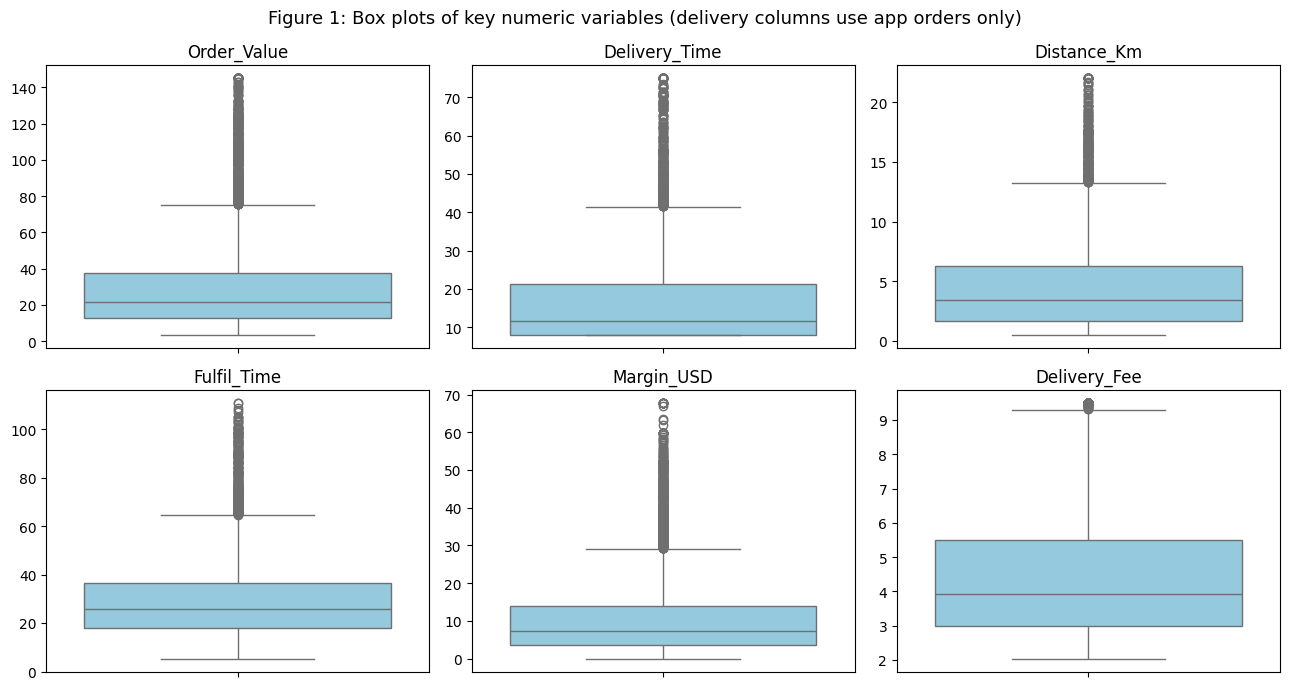

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

out_cols = ["Order_Value", "Delivery_Time", "Distance_Km", "Fulfil_Time", "Margin_USD", "Delivery_Fee"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()
for i, col in enumerate(out_cols):
    data = app[col] if col in ["Delivery_Time", "Distance_Km", "Delivery_Fee"] else df[col]
    sns.boxplot(y=data, ax=axes[i], color="skyblue")
    axes[i].set_title(col); axes[i].set_ylabel("")
fig.suptitle("Figure 1: Box plots of key numeric variables (delivery columns use app orders only)", fontsize=13)
plt.tight_layout(); plt.show()

In [25]:
def iqr_table(frame_map):
    rows = []
    for col, data in frame_map.items():
        q1, q3 = data.quantile(0.25), data.quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((data < lo) | (data > hi)).sum())
        rows.append([col, round(q1, 2), round(q3, 2), round(iqr, 2), round(lo, 2), round(hi, 2), n_out,
                     round(n_out / len(data) * 100, 1)])
    return pd.DataFrame(rows, columns=["Variable", "Q1", "Q3", "IQR", "Lower fence", "Upper fence", "Count outside", "% outside"])

frame_map = {c: (app[c] if c in ["Delivery_Time", "Distance_Km", "Delivery_Fee"] else df[c]) for c in out_cols}
outlier_table = iqr_table(frame_map)
outlier_table

,Variable,Q1,Q3,IQR,Lower fence,Upper fence,Count outside,% outside
0,Order_Value,12.92,37.89,24.97,-24.54,75.35,558,7.0
1,Delivery_Time,8.00,21.40,13.40,-12.10,41.50,358,6.8
2,Distance_Km,1.70,6.30,4.60,-5.20,13.20,249,4.7
3,Fulfil_Time,18.00,36.70,18.70,-10.05,64.75,308,3.9
4,Margin_USD,3.73,13.91,10.18,-11.55,29.19,563,7.0
5,Delivery_Fee,2.98,5.51,2.53,-0.82,9.30,260,4.9


In [26]:
# Look at the flagged rows before deciding (Retain / Remove / Cap / Investigate)
print(df[df["Order_Value"] > 100][["Order_ID", "City", "Price_Tier", "Order_Value", "Margin_USD"]].head(8))
print("\nPremium share among orders above the upper fence:")
hi = outlier_table.loc[outlier_table.Variable == "Order_Value", "Upper fence"].iloc[0]
print(df[df["Order_Value"] > hi]["Price_Tier"].value_counts(normalize=True).round(2))

# Example of CAPPING (Lecture 6 method) on Order_Value - for comparison only
q1, q3 = df["Order_Value"].quantile([.25, .75]); iqr = q3 - q1
df["Order_Value_Capped"] = df["Order_Value"].clip(q1 - 1.5*iqr, q3 + 1.5*iqr)
print("\nMean before capping:", round(df["Order_Value"].mean(), 2), "| after capping:", round(df["Order_Value_Capped"].mean(), 2))
print("Max before:", df["Order_Value"].max(), "| max after:", round(df["Order_Value_Capped"].max(), 2))

# YOUR DECISION (edit in your own words): usually RETAIN, because large orders are real premium orders.
decision = {"Order_Value": "Retain / Cap?", "Delivery_Time": "Retain", "Distance_Km": "Retain",
            "Fulfil_Time": "Retain", "Margin_USD": "Retain", "Delivery_Fee": "Retain"}
decision

             Order_ID    City                 Price_Tier  Order_Value  \
4    ord_059fca6f1251  Berlin  $$$ Premium / Fine Dining       121.46   
126  ord_fab06865b024  Berlin  $$$ Premium / Fine Dining       104.68   
162  ord_82bcfb8a10f8  Berlin  $$$ Premium / Fine Dining       123.02   
163  ord_9298d97b6f78  Berlin  $$$ Premium / Fine Dining       104.07   
167  ord_b5caa1f64e84  Berlin  $$$ Premium / Fine Dining       138.19   
232  ord_a76d9282854e  Berlin  $$$ Premium / Fine Dining       102.86   
255  ord_f56655d8b48a  Berlin  $$$ Premium / Fine Dining       145.00   
298  ord_8a6da5dabe55  Berlin  $$$ Premium / Fine Dining       145.00   

     Margin_USD  
4         43.44  
126       37.23  
162       57.52  
163       42.51  
167       49.63  
232       48.04  
255       52.15  
298       52.15  

Premium share among orders above the upper fence:
Price_Tier
$$$ Premium / Fine Dining    0.89
$$ Moderate                  0.11
Name: proportion, dtype: float64

Mean before capp

{'Order_Value': 'Retain / Cap?',
 'Delivery_Time': 'Retain',
 'Distance_Km': 'Retain',
 'Fulfil_Time': 'Retain',
 'Margin_USD': 'Retain',
 'Delivery_Fee': 'Retain'}

Step 2.4 | Group-wise summaries and EDA observations

In [27]:
g1 = df.groupby("City").agg(Orders=("Order_ID","count"), Avg_Value=("Order_Value","mean"),
                            Avg_Margin=("Margin_USD","mean"), Avg_Rating=("Rating","mean")).round(2).sort_values("Avg_Value", ascending=False)
g1

,Orders,Avg_Value,Avg_Margin,Avg_Rating
City,,,,
London,807,31.61,11.27,4.26
Mumbai,493,31.11,11.14,4.30
Toronto,464,30.82,11.14,4.30
Paris,603,30.82,11.00,4.30
Sydney,575,30.55,10.99,4.29
Tokyo,914,30.53,10.99,4.33
Seoul,502,30.44,10.87,4.26
New York,1010,29.99,10.59,4.26
Singapore,676,29.65,10.57,4.28


In [28]:
g2 = app.groupby("Weather").agg(Orders=("Order_ID","count"), Avg_Delivery_Min=("Delivery_Time","mean"),
                                Avg_Fulfil_Min=("Fulfil_Time","mean"), Avg_Rating=("Rating","mean")).round(2)
g2

,Orders,Avg_Delivery_Min,Avg_Fulfil_Min,Avg_Rating
Weather,,,,
Clear,2870,15.96,34.97,4.27
Cloudy / Fog,795,15.50,34.46,4.28
Heavy Rain / Storm,431,24.13,43.30,3.86
Rainy,1159,18.67,37.66,4.24


In [29]:
g3 = app.groupby("Peak_Hour").agg(Orders=("Order_ID","count"), Avg_Delivery_Min=("Delivery_Time","mean"),
                                  Avg_Fulfil_Min=("Fulfil_Time","mean"), Avg_Rating=("Rating","mean")).round(2)
g3

,Orders,Avg_Delivery_Min,Avg_Fulfil_Min,Avg_Rating
Peak_Hour,,,,
False,3114,14.87,30.76,4.30
True,2141,20.49,44.03,4.12


In [30]:
g4 = df.groupby("Cuisine").agg(Orders=("Order_ID","count"), Avg_Value=("Order_Value","mean"),
                               Avg_Margin=("Margin_USD","mean"), Avg_Rating=("Rating","mean")).round(2).sort_values("Avg_Margin", ascending=False)
g4

,Orders,Avg_Value,Avg_Margin,Avg_Rating
Cuisine,,,,
Japanese & Sushi,1459,32.04,11.54,4.27
Indian & Curries,784,31.15,11.16,4.26
Healthy & Bowls,862,30.26,10.79,4.29
Indonesian & Asian Street Food,1203,29.94,10.65,4.28
Mexican & Tacos,659,29.55,10.54,4.28
Burgers & Fast Food,1788,29.45,10.48,4.31
Italian & Pizza,1245,29.22,10.38,4.28


In [31]:
g5 = df.groupby("Channel").agg(Orders=("Order_ID","count"), Avg_Value=("Order_Value","mean"),
                               Avg_Margin=("Margin_USD","mean"), Avg_Rating=("Rating","mean"),
                               Avg_Discount_Pct=("Discount_Pct","mean")).round(2)
g5

,Orders,Avg_Value,Avg_Margin,Avg_Rating,Avg_Discount_Pct
Channel,,,,,
Dine-In POS,1577,30.29,13.94,4.39,11.46
Online Delivery App,5255,29.92,9.57,4.23,12.02
Takeaway / Pickup,1168,31.49,12.02,4.37,12.04


In [32]:
# Observation statements (Pattern, Gap, Trend, Outlier) - the code prints the numbers you will quote
best_city = g1["Avg_Value"].idxmax(); worst_city = g1["Avg_Value"].idxmin()
print("PATTERN: highest average order value:", best_city, round(g1["Avg_Value"].max(), 2), "USD")
print("GAP    : lowest average order value :", worst_city, round(g1["Avg_Value"].min(), 2), "USD")
print("TREND  : peak vs non-peak delivery time (min):",
      g3.loc[True, "Avg_Delivery_Min"], "vs", g3.loc[False, "Avg_Delivery_Min"],
      "->", pct_change(g3.loc[True, "Avg_Delivery_Min"], g3.loc[False, "Avg_Delivery_Min"]), "% change")
print("OUTLIER: orders above the order-value upper fence:",
      int(outlier_table.loc[outlier_table.Variable=="Order_Value","Count outside"].iloc[0]))

PATTERN: highest average order value: London 31.61 USD
GAP    : lowest average order value : Berlin 28.63 USD
TREND  : peak vs non-peak delivery time (min): 20.49 vs 14.87 -> 37.8 % change
OUTLIER: orders above the order-value upper fence: 558


MODULE 3 — Visualisation, statistics and relationships

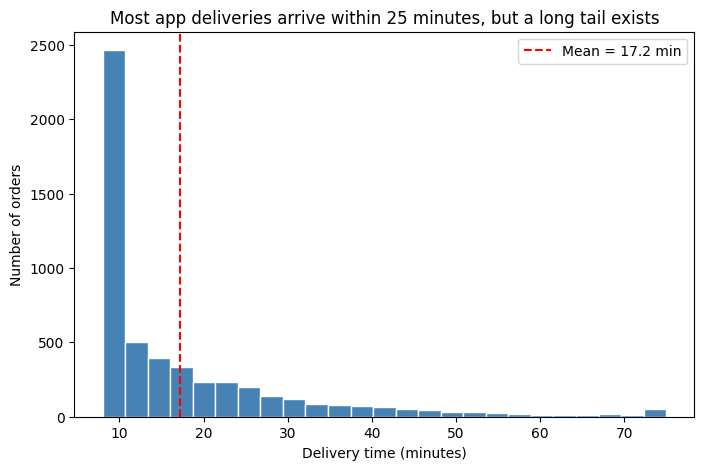

In [33]:
plt.figure(figsize=(8, 5))
plt.hist(app["Delivery_Time"], bins=25, color="steelblue", edgecolor="white")
plt.axvline(app["Delivery_Time"].mean(), color="red", linestyle="--", label=f"Mean = {app['Delivery_Time'].mean():.1f} min")
plt.title("Most app deliveries arrive within 25 minutes, but a long tail exists")
plt.xlabel("Delivery time (minutes)"); plt.ylabel("Number of orders"); plt.legend(); plt.show()

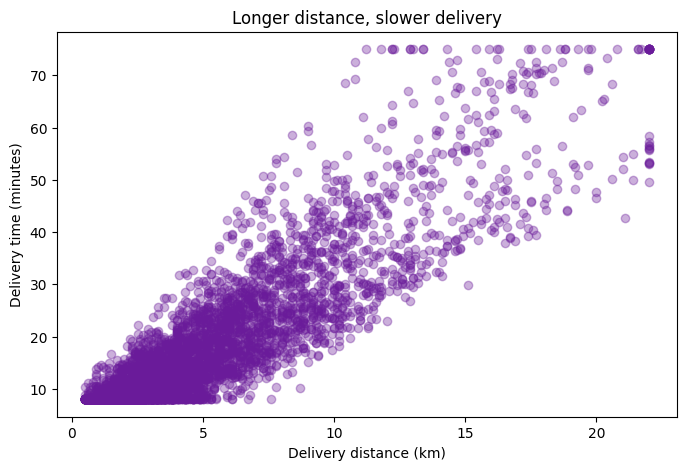

In [34]:
plt.figure(figsize=(8, 5))
plt.scatter(app["Distance_Km"], app["Delivery_Time"], alpha=0.35, color="#6A1B9A")
plt.title("Longer distance, slower delivery")
plt.xlabel("Delivery distance (km)"); plt.ylabel("Delivery time (minutes)"); plt.show()

Line plot — average rating as distance band grows

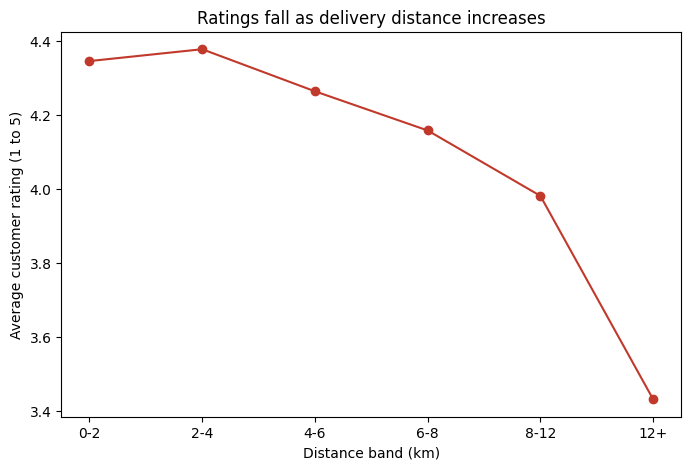

Distance_Band
0-2     4.35
2-4     4.38
4-6     4.26
6-8     4.16
8-12    3.98
12+     3.43
Name: Rating, dtype: float64


In [35]:
app["Distance_Band"] = pd.cut(app["Distance_Km"], bins=[0, 2, 4, 6, 8, 12, 25],
                              labels=["0-2", "2-4", "4-6", "6-8", "8-12", "12+"], include_lowest=True)
line_data = app.groupby("Distance_Band", observed=True)["Rating"].mean()

plt.figure(figsize=(8, 5))
plt.plot(line_data.index.astype(str), line_data.values, marker="o", color="#C0392B")
plt.title("Ratings fall as delivery distance increases")
plt.xlabel("Distance band (km)"); plt.ylabel("Average customer rating (1 to 5)"); plt.show()
print(line_data.round(2))

Area plot — satisfaction mix by distance band

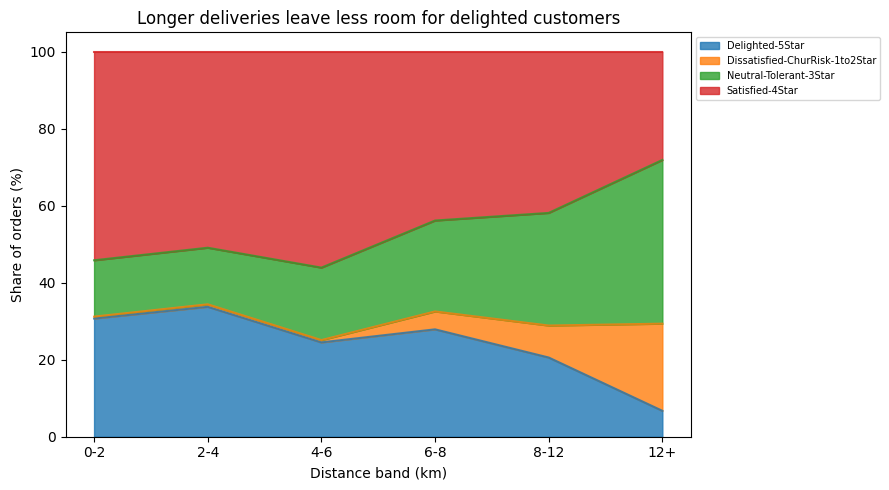

In [36]:
mix = pd.crosstab(app["Distance_Band"], app["Satisfaction_Tier"], normalize="index") * 100
mix.plot(kind="area", stacked=True, alpha=0.8, figsize=(9, 5))
plt.title("Longer deliveries leave less room for delighted customers")
plt.xlabel("Distance band (km)"); plt.ylabel("Share of orders (%)")
plt.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

Bar plot — which cuisine earns the most margin per order?

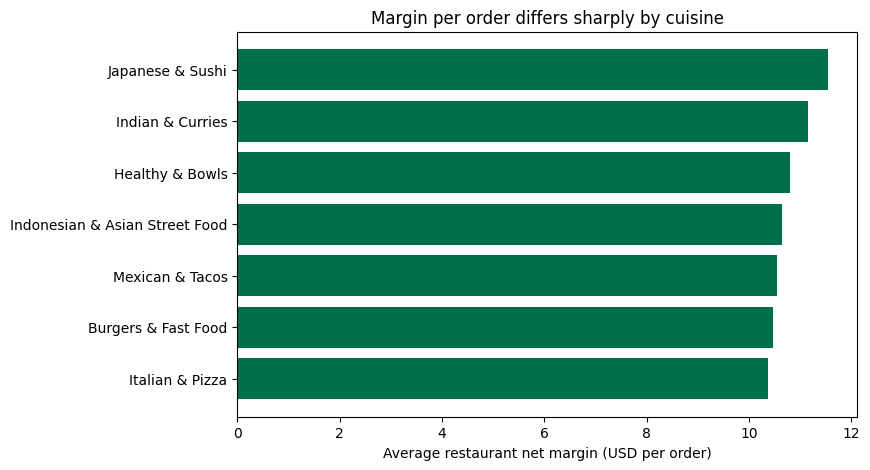

Cuisine
Italian & Pizza                   10.38
Burgers & Fast Food               10.48
Mexican & Tacos                   10.54
Indonesian & Asian Street Food    10.65
Healthy & Bowls                   10.79
Indian & Curries                  11.16
Japanese & Sushi                  11.54
Name: Margin_USD, dtype: float64


In [37]:
cm = df.groupby("Cuisine")["Margin_USD"].mean().sort_values()
plt.figure(figsize=(8, 5))
plt.barh(cm.index, cm.values, color="#00704A")
plt.title("Margin per order differs sharply by cuisine")
plt.xlabel("Average restaurant net margin (USD per order)"); plt.show()
print(cm.round(2))

Count plot — orders by channel in each city

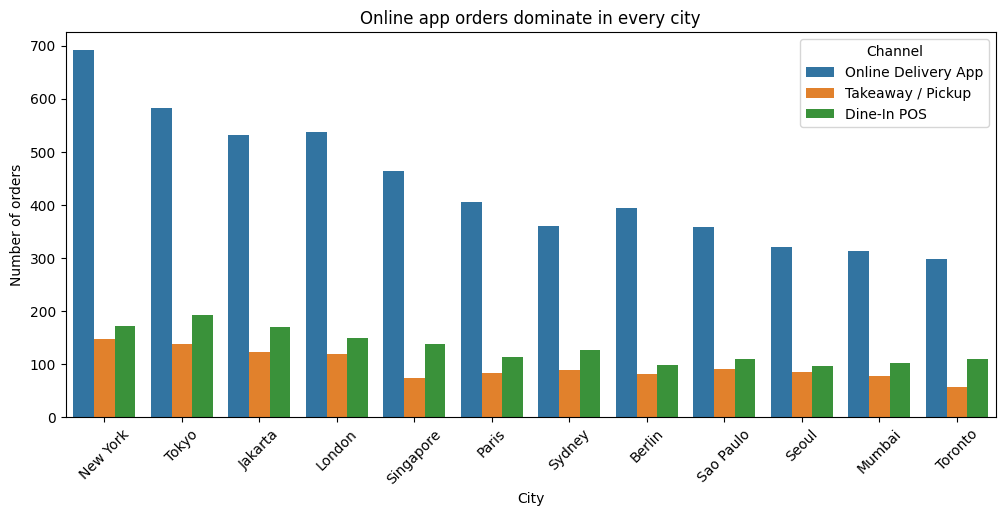

In [38]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="City", hue="Channel", order=df["City"].value_counts().index)
plt.title("Online app orders dominate in every city")
plt.xlabel("City"); plt.ylabel("Number of orders"); plt.xticks(rotation=45); plt.show()

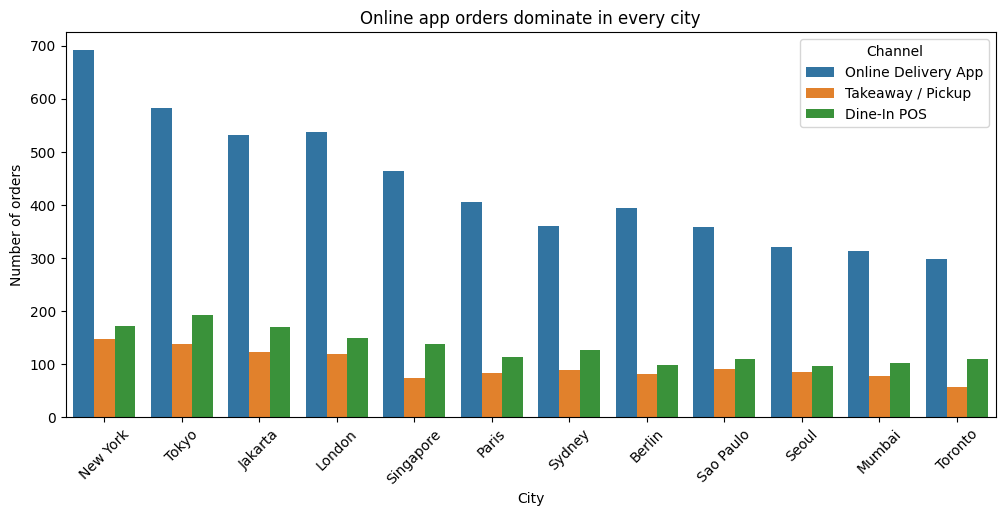

In [39]:
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x="City", hue="Channel", order=df["City"].value_counts().index)
plt.title("Online app orders dominate in every city")
plt.xlabel("City"); plt.ylabel("Number of orders"); plt.xticks(rotation=45); plt.show()

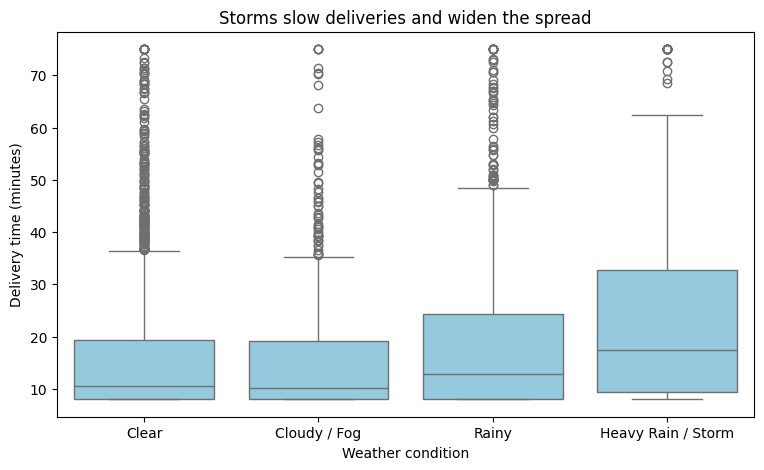

In [40]:
w_order = ["Clear", "Cloudy / Fog", "Rainy", "Heavy Rain / Storm"]
plt.figure(figsize=(9, 5))
sns.boxplot(data=app, x="Weather", y="Delivery_Time", order=w_order, color="skyblue")
plt.title("Storms slow deliveries and widen the spread")
plt.xlabel("Weather condition"); plt.ylabel("Delivery time (minutes)"); plt.show()

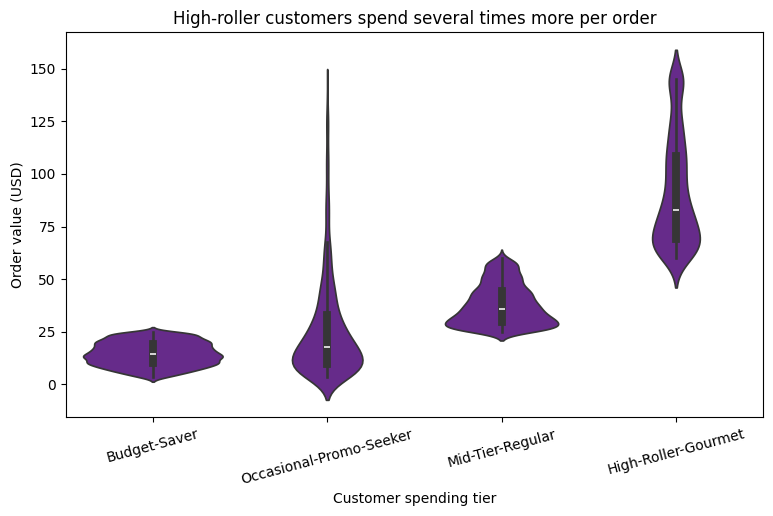

In [41]:
t_order = ["Budget-Saver", "Occasional-Promo-Seeker", "Mid-Tier-Regular", "High-Roller-Gourmet"]
plt.figure(figsize=(9, 5))
sns.violinplot(data=df, x="Spend_Tier", y="Order_Value", order=t_order, color="#6A1B9A")
plt.title("High-roller customers spend several times more per order")
plt.xlabel("Customer spending tier"); plt.ylabel("Order value (USD)"); plt.xticks(rotation=15); plt.show()

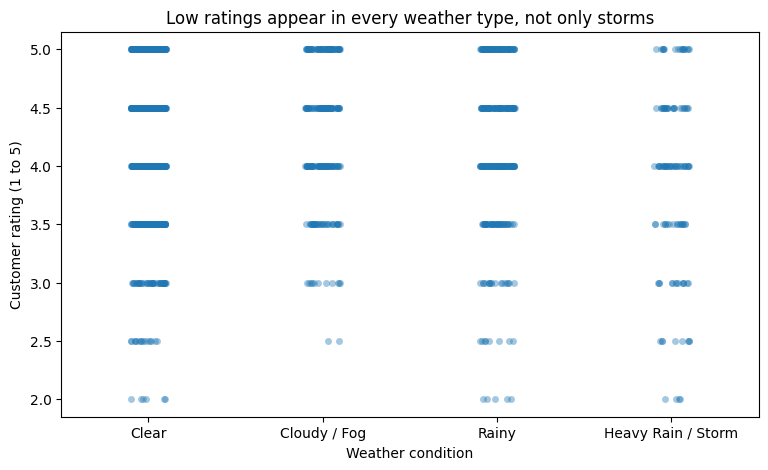

In [42]:
plt.figure(figsize=(9, 5))
sns.stripplot(data=app.sample(1500, random_state=1), x="Weather", y="Rating", order=w_order, jitter=True, alpha=0.4)
plt.title("Low ratings appear in every weather type, not only storms")
plt.xlabel("Weather condition"); plt.ylabel("Customer rating (1 to 5)"); plt.show()

/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 20.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.13/dist-packages/seaborn/categorical.py:3399: UserWarning: 11.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


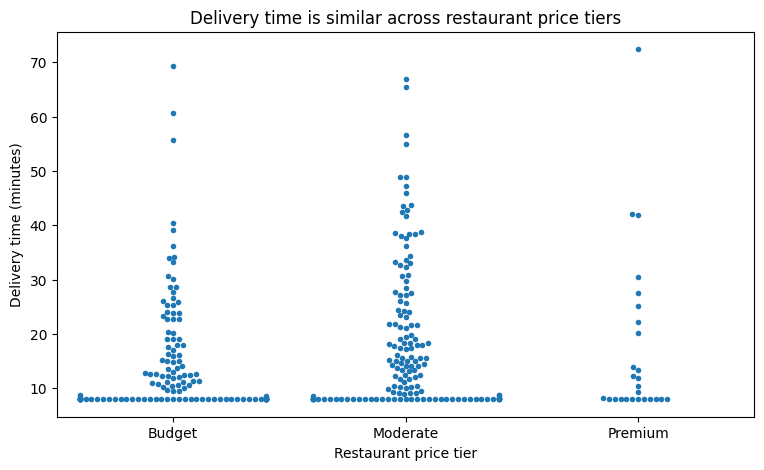

In [43]:
pt_order = ["Budget", "Moderate", "Premium"]
plt.figure(figsize=(9, 5))
sns.swarmplot(data=app.sample(300, random_state=1), x="Price_Label", y="Delivery_Time", order=pt_order, size=4)
plt.title("Delivery time is similar across restaurant price tiers")
plt.xlabel("Restaurant price tier"); plt.ylabel("Delivery time (minutes)"); plt.show()

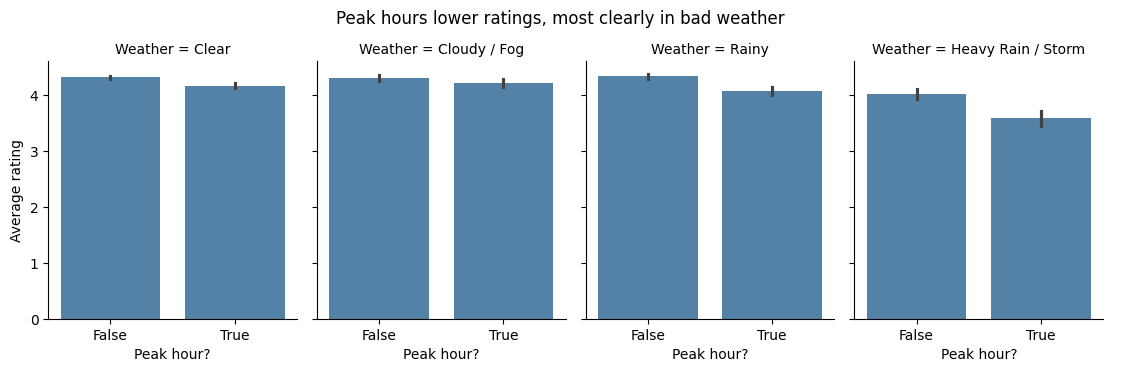

In [44]:
g = sns.catplot(data=app, x="Peak_Hour", y="Rating", col="Weather", col_order=w_order, kind="bar", height=3.5, aspect=0.8, color="steelblue")
g.set_axis_labels("Peak hour?", "Average rating")
g.fig.suptitle("Peak hours lower ratings, most clearly in bad weather", y=1.05)
plt.show()

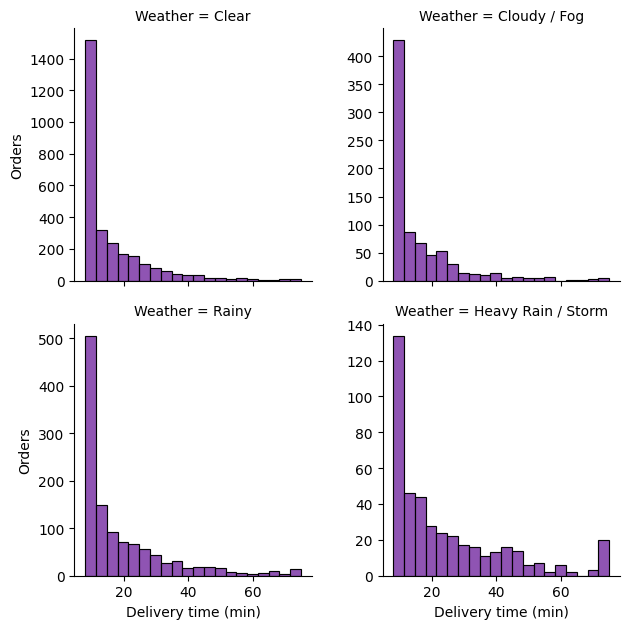

In [45]:
g = sns.FacetGrid(app, col="Weather", col_order=w_order, col_wrap=2, height=3.2, sharey=False)
g.map(sns.histplot, "Delivery_Time", bins=20, color="#6A1B9A")
g.set_axis_labels("Delivery time (min)", "Orders")
plt.show()

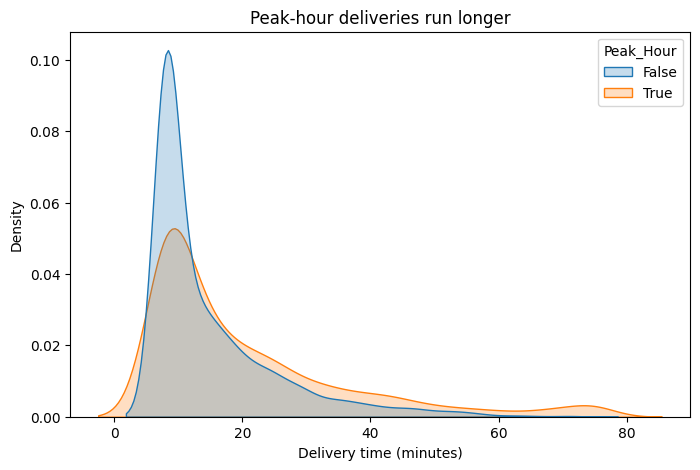

In [46]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=app, x="Delivery_Time", hue="Peak_Hour", fill=True, common_norm=False)
plt.title("Peak-hour deliveries run longer")
plt.xlabel("Delivery time (minutes)"); plt.ylabel("Density"); plt.show()

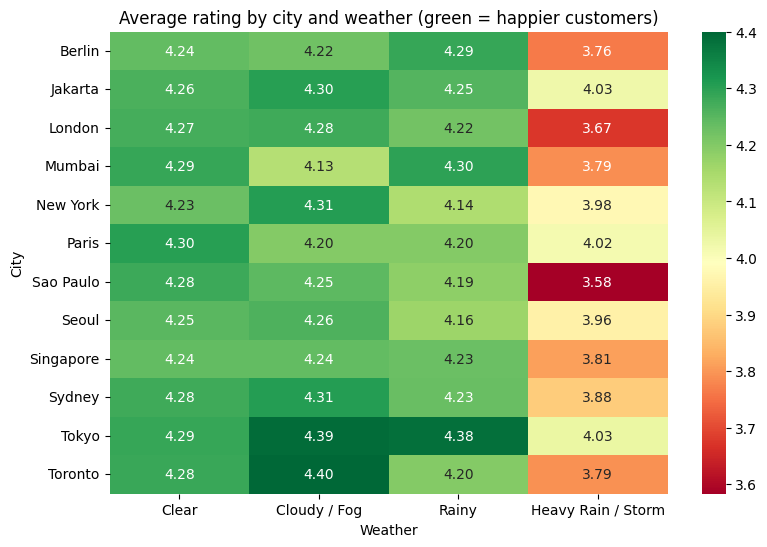

In [47]:
hm = app.pivot_table(index="City", columns="Weather", values="Rating", aggfunc="mean")[w_order]
plt.figure(figsize=(9, 6))
sns.heatmap(hm, annot=True, fmt=".2f", cmap="RdYlGn")
plt.title("Average rating by city and weather (green = happier customers)")
plt.show()

Part C | Relationships: correlation

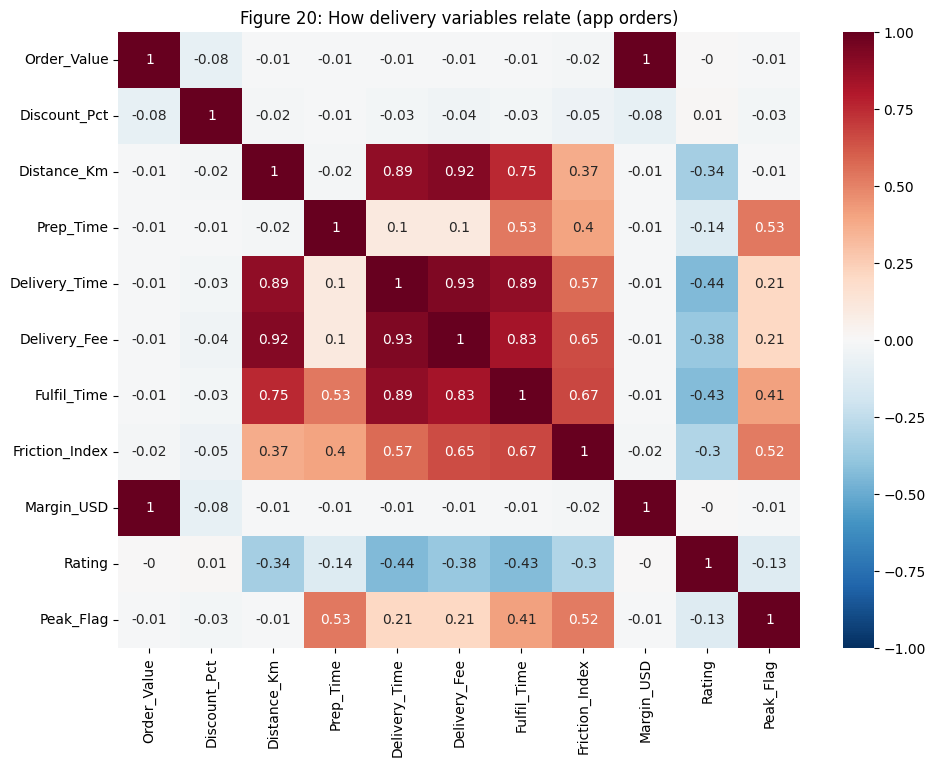

In [48]:
corr_cols = ["Order_Value", "Discount_Pct", "Distance_Km", "Prep_Time", "Delivery_Time", "Delivery_Fee",
             "Fulfil_Time", "Friction_Index", "Margin_USD", "Rating", "Peak_Flag"]
corr_app = app[corr_cols].corr().round(2)

plt.figure(figsize=(11, 8))
sns.heatmap(corr_app, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Figure 20: How delivery variables relate (app orders)")
plt.show()

In [49]:
# The strongest pairs, ranked (ignore the diagonal)
pairs = corr_app.where(np.triu(np.ones(corr_app.shape), k=1).astype(bool)).stack().reset_index()
pairs.columns = ["Var 1", "Var 2", "r"]
pairs["abs_r"] = pairs["r"].abs()
print("Top 5 strongest relationships:")
print(pairs.sort_values("abs_r", ascending=False).head(5).drop(columns="abs_r").to_string(index=False))
print("\nWeakest pairs (possible 'surprise: no relationship'):")
print(pairs.sort_values("abs_r").head(3).drop(columns="abs_r").to_string(index=False))

Top 5 strongest relationships:
        Var 1         Var 2    r
  Order_Value    Margin_USD 1.00
Delivery_Time  Delivery_Fee 0.93
  Distance_Km  Delivery_Fee 0.92
Delivery_Time   Fulfil_Time 0.89
  Distance_Km Delivery_Time 0.89

Weakest pairs (possible 'surprise: no relationship'):
      Var 1         Var 2     r
Order_Value        Rating -0.00
 Margin_USD        Rating -0.00
Order_Value Delivery_Time -0.01


In [50]:
r1 = app["Delivery_Time"].corr(app["Rating"])
r2 = app["Delivery_Fee"].corr(app["Rating"])
r3 = df["Discount_Pct"].corr(df["Margin_USD"])
r4 = df["Order_Value"].corr(df["Rating"])
print("Delivery time and rating :", round(r1, 2))
print("Delivery fee and rating  :", round(r2, 2))
print("Discount % and margin    :", round(r3, 2))
print("Order value and rating   :", round(r4, 2), "(close to zero: spending does not buy satisfaction)")
print("\nCorrelation is not causation: long delivery time and low rating move together, but distance,")
print("fee and weather also move with both, so time alone may not be the cause.")
results.update(r_time_rating=round(r1, 2), r_fee_rating=round(r2, 2), r_disc_margin=round(r3, 2))

Delivery time and rating : -0.44
Delivery fee and rating  : -0.38
Discount % and margin    : -0.09
Order value and rating   : 0.01 (close to zero: spending does not buy satisfaction)

Correlation is not causation: long delivery time and low rating move together, but distance,
fee and weather also move with both, so time alone may not be the cause.


Part D | Regression

In [52]:
# Simple linear regression: Rating ~ Delivery_Time (app orders)
import statsmodels.formula.api as smf

m1 = smf.ols("Rating ~ Delivery_Time", data=app).fit()
print(m1.summary().tables[1])
print("R-squared:", round(m1.rsquared, 3))
print("Equation: Rating =", round(m1.params["Intercept"], 3), "+", round(m1.params["Delivery_Time"], 4), "x Delivery_Time")
print("Each extra 10 minutes of delivery time changes rating by", round(m1.params["Delivery_Time"]*10, 2))
results.update(slope_time=round(m1.params["Delivery_Time"], 4), r2_simple=round(m1.rsquared, 3))

                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         4.6132      0.014    334.267      0.000       4.586       4.640
Delivery_Time    -0.0224      0.001    -35.328      0.000      -0.024      -0.021
R-squared: 0.192
Equation: Rating = 4.613 + -0.0224 x Delivery_Time
Each extra 10 minutes of delivery time changes rating by -0.22


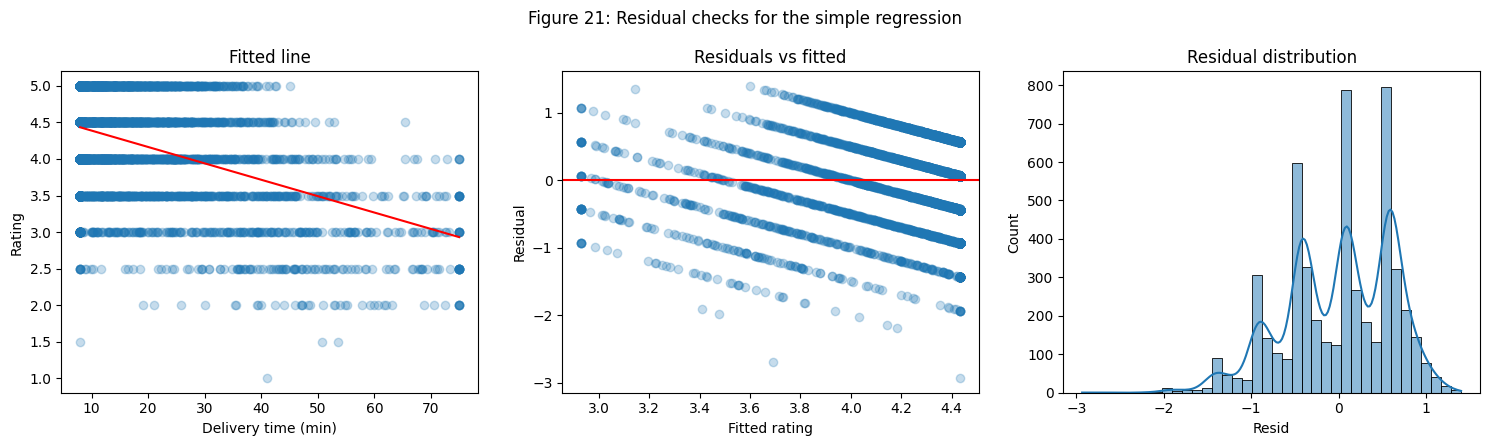

Ratings are capped at 5, so residuals are not perfectly normal: state this as a limit.


In [53]:
# Residual check
app["Pred_Rating"] = m1.fittedvalues
app["Resid"] = m1.resid

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].scatter(app["Delivery_Time"], app["Rating"], alpha=0.25)
order = app["Delivery_Time"].sort_values().index
axes[0].plot(app.loc[order, "Delivery_Time"], app.loc[order, "Pred_Rating"], color="red")
axes[0].set_title("Fitted line"); axes[0].set_xlabel("Delivery time (min)"); axes[0].set_ylabel("Rating")
axes[1].scatter(app["Pred_Rating"], app["Resid"], alpha=0.25)
axes[1].axhline(0, color="red"); axes[1].set_title("Residuals vs fitted"); axes[1].set_xlabel("Fitted rating"); axes[1].set_ylabel("Residual")
sns.histplot(app["Resid"], kde=True, ax=axes[2]); axes[2].set_title("Residual distribution")
plt.suptitle("Figure 21: Residual checks for the simple regression")
plt.tight_layout(); plt.show()
print("Ratings are capped at 5, so residuals are not perfectly normal: state this as a limit.")

In [55]:
# One prediction example for a manager
for minutes in [10, 25, 45]:
    pred = m1.predict(pd.DataFrame({"Delivery_Time": [minutes]}))[0]
    print(f"Delivery time {minutes} min -> expected rating {pred:.2f}")

Delivery time 10 min -> expected rating 4.39
Delivery time 25 min -> expected rating 4.05
Delivery time 45 min -> expected rating 3.60


In [56]:
# Multiple regression: what slows fulfilment?  (Problem 1)
m2 = smf.ols("Fulfil_Time ~ Distance_Km + Prep_Time + Peak_Flag + C(Weather, Treatment('Clear'))", data=app).fit()
print(m2.summary().tables[1])
print("R-squared:", round(m2.rsquared, 3))
results.update(r2_multi=round(m2.rsquared, 3))

                                                           coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------
Intercept                                               -0.3518      0.213     -1.655      0.098      -0.769       0.065
C(Weather, Treatment('Clear'))[T.Cloudy / Fog]           0.0660      0.187      0.353      0.724      -0.300       0.432
C(Weather, Treatment('Clear'))[T.Heavy Rain / Storm]     8.2414      0.241     34.211      0.000       7.769       8.714
C(Weather, Treatment('Clear'))[T.Rainy]                  3.0404      0.162     18.740      0.000       2.722       3.358
Distance_Km                                              2.9659      0.016    185.651      0.000       2.935       2.997
Prep_Time                                                0.9966      0.011     93.429      0.000       0.976       1.018
Peak_Flag                       

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           30.6593      0.134    228.466      0.000      30.396      30.922
Dist_c               2.3428      0.034     69.532      0.000       2.277       2.409
Peak_Flag           13.6078      0.210     64.722      0.000      13.196      14.020
Dist_c:Peak_Flag     1.4219      0.052     27.354      0.000       1.320       1.524
R-squared: 0.773


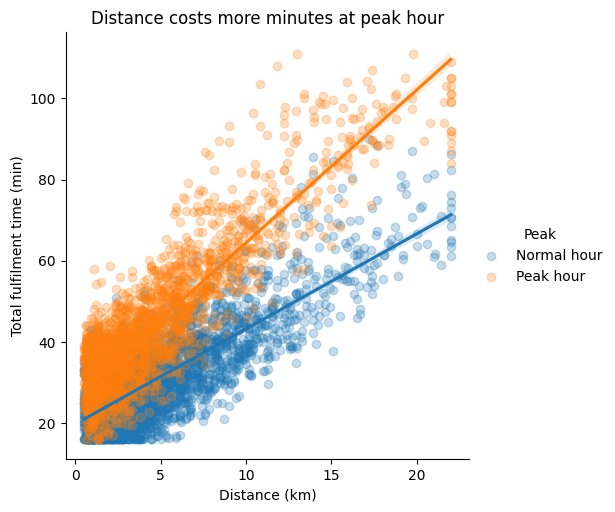

In [57]:
# Does the effect of distance change at peak hour? (interaction / moderation, Lecture 14 style)
app["Dist_c"] = app["Distance_Km"] - app["Distance_Km"].mean()
m3 = smf.ols("Fulfil_Time ~ Dist_c * Peak_Flag", data=app).fit()
print(m3.summary().tables[1]); print("R-squared:", round(m3.rsquared, 3))

g = sns.lmplot(data=app.assign(Peak=np.where(app["Peak_Hour"], "Peak hour", "Normal hour")),
               x="Distance_Km", y="Fulfil_Time", hue="Peak", height=5, scatter_kws={"alpha": 0.25})
g.set(title="Distance costs more minutes at peak hour", xlabel="Distance (km)", ylabel="Total fulfilment time (min)")
plt.show()

In [58]:
# Discount and margin (Problem 3): control for order value
m4a = smf.ols("Margin_USD ~ Discount_Pct", data=df).fit()
m4b = smf.ols("Margin_USD ~ Discount_Pct + Order_Value", data=df).fit()
print("Discount % alone   : coef", round(m4a.params['Discount_Pct'], 3), "| p =", round(m4a.pvalues['Discount_Pct'], 4), "| R2", round(m4a.rsquared, 3))
print("With Order_Value   : coef", round(m4b.params['Discount_Pct'], 3), "| p =", round(m4b.pvalues['Discount_Pct'], 4), "| R2", round(m4b.rsquared, 3))

df["Discount_Band"] = pd.cut(df["Discount_Pct"], bins=[-0.1, 0, 10, 20, 30, 40], labels=["0", "0-10", "10-20", "20-30", "30-40"])
band_tbl = df.groupby("Discount_Band", observed=True).agg(Orders=("Order_ID","count"), Avg_Margin=("Margin_USD","mean"),
                                                          Loss_Making=("Margin_USD", lambda s: (s <= 0).sum())).round(2)
band_tbl

Discount % alone   : coef -0.076 | p = 0.0 | R2 0.008
With Order_Value   : coef -0.003 | p = 0.1283 | R2 0.966


,Orders,Avg_Margin,Loss_Making
Discount_Band,,,
0,3332,10.81,34
0-10,722,15.50,0
10-20,1495,10.84,0
20-30,1613,10.12,18
30-40,838,7.84,39


PCA

In [59]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

pca_cols = ["Distance_Km", "Delivery_Time", "Speed_Kmh", "Fulfil_Time", "Prep_Time", "Delivery_Fee", "Fee_Ratio", "Friction_Index"]
print(app[pca_cols].corr().round(2))

scaled = StandardScaler().fit_transform(app[pca_cols])
pca = PCA()
scores = pca.fit_transform(scaled)

names = [f"PC{i+1}" for i in range(len(pca_cols))]
var_table = pd.DataFrame({"Variance explained": pca.explained_variance_ratio_.round(3),
                          "Cumulative": pca.explained_variance_ratio_.cumsum().round(3)}, index=names)
print(var_table)

                Distance_Km  Delivery_Time  Speed_Kmh  Fulfil_Time  Prep_Time  \
Distance_Km            1.00           0.89       0.46         0.75      -0.02   
Delivery_Time          0.89           1.00       0.10         0.89       0.10   
Speed_Kmh              0.46           0.10       1.00         0.01      -0.18   
Fulfil_Time            0.75           0.89       0.01         1.00       0.53   
Prep_Time             -0.02           0.10      -0.18         0.53       1.00   
Delivery_Fee           0.92           0.93       0.31         0.83       0.10   
Fee_Ratio              0.40           0.39       0.15         0.35       0.04   
Friction_Index         0.37           0.57      -0.17         0.67       0.40   

                Delivery_Fee  Fee_Ratio  Friction_Index  
Distance_Km             0.92       0.40            0.37  
Delivery_Time           0.93       0.39            0.57  
Speed_Kmh               0.31       0.15           -0.17  
Fulfil_Time             0.83       0.3

NameError: name 'StandardScaler' is not defined

Loadings (which variables define each component):
                 PC1   PC2   PC3
Distance_Km     0.43  0.30 -0.13
Delivery_Time   0.45  0.04  0.04
Speed_Kmh       0.11  0.59 -0.47
Fulfil_Time     0.45 -0.23 -0.15
Prep_Time       0.13 -0.58 -0.40
Delivery_Fee    0.46  0.12 -0.04
Fee_Ratio       0.24  0.13  0.75
Friction_Index  0.33 -0.37  0.12


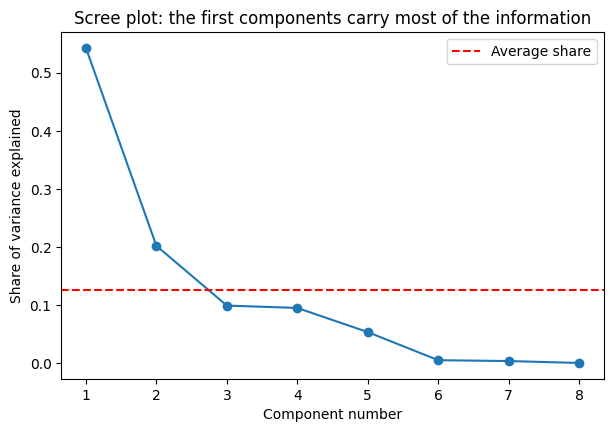

In [61]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Ensure data is scaled and PCA is fitted
scaled = StandardScaler().fit_transform(app[pca_cols])
pca = PCA()
pca.fit(scaled)
names = [f"PC{i+1}" for i in range(len(pca_cols))]

# Create and print loadings
loadings = pd.DataFrame(pca.components_[:3].T, index=pca_cols, columns=["PC1", "PC2", "PC3"]).round(2)
print("Loadings (which variables define each component):")
print(loadings)

# Plot scree plot
plt.figure(figsize=(7, 4.5))
plt.plot(range(1, len(names)+1), pca.explained_variance_ratio_, marker="o")
plt.axhline(1/len(names), color="red", linestyle="--", label="Average share")
plt.title("Scree plot: the first components carry most of the information")
plt.xlabel("Component number"); plt.ylabel("Share of variance explained"); plt.legend(); plt.show()

Save outputs (Excel workbook for submission) and

In [62]:
out_name = "26PGDM012_EktaSingh_CaseAssessment.xlsx"
with pd.ExcelWriter(out_name, engine="openpyxl") as writer:
    raw.drop(columns=["Rationale"]).to_excel(writer, sheet_name="Raw_Data", index=False)
    df.drop(columns=["Rationale"]).to_excel(writer, sheet_name="Cleaned_Data", index=False)
    quality_table.to_excel(writer, sheet_name="Quality_Log")
    outlier_table.to_excel(writer, sheet_name="Outliers", index=False)
    g1.to_excel(writer, sheet_name="By_City"); g4.to_excel(writer, sheet_name="By_Cuisine")
    g2.to_excel(writer, sheet_name="By_Weather"); g3.to_excel(writer, sheet_name="By_Peak_Hour")
    stats_table.to_excel(writer, sheet_name="Statistics", index=False)
    corr_app.to_excel(writer, sheet_name="Correlation")
    var_table.to_excel(writer, sheet_name="PCA_Variance"); loadings.to_excel(writer, sheet_name="PCA_Loadings")
    band_tbl.to_excel(writer, sheet_name="Discount_Bands"); city_score.to_frame("Friction_Score").to_excel(writer, sheet_name="City_Friction")
print("Saved:", out_name)

try:
    from google.colab import files
    files.download(out_name)
except ImportError:
    pass

NameError: name 'stats_table' is not defined